# Tools - Random walk dimension ($d_{rw}$) of a network

- Random walk dimension of a network
- other tools for random walks in a netorwk

*Note. Presented tool works on `networkx.Graph` objects. A `KGraph` object `kg` can be defined from a `networkx.Graph` graph `g` with `kg = kn.from_networkx(g)`.*

## Random walk dimension
For random walks in the graph, the mean Euclidean square distance (from the starting node), $R^2$, should follow a power law
- $R^2 \propto t^{2/d_{rw}}$

where $t$ is the (number of) time step(s). The number $d_{rw}$ is the **random walk dimension** (also called **fractal dimension of the random walk**). 

### Computation of random walk dimension

The random walk dimension can be statistically computed by performing an ensemble of random walks. The starting node is randomly chosen, and at each (time) step $t$, the walker being at node $X_t$, an edge whose one of the extremity is $X_t$ is randomly selected (with probabilities proportional to edge weights, edge weights are all set to one if not specified) and the walker follows this edge to go the the next node $X_{t+1}$. 

To consider "resistance" along edges, one can take edge weights proportional to the inverse of their length.

The exponent $\beta=2/d_{rw}$ is obtained by fitting a line on the log-log plot of $R^2$ as function of $t$.

The dedicated function is `kn.tools.graph_random_walk_dimension`.

In [1]:
import networkx as nx
import numpy as np 
import matplotlib.pyplot as plt
import scipy
# import time
# import tqdm
# import functools


In [2]:
# Choose matplotlib backend
# -------------------------
# 'inline' : inline plot (non-interactive)
# 'widget' : interactive plot
# 'tk'     : plot in a pop-up window (interactive)
from IPython import get_ipython
get_ipython().run_line_magic('matplotlib', 'inline')
# get_ipython().run_line_magic('matplotlib', 'widget')
# get_ipython().run_line_magic('matplotlib', 'tk')

# Or simply:
# %matplotlib inline
# %matplotlib widget
# %matplotlib tk


In [3]:
# import pyvista as pv

# # Choose backend for pyvista with jupyter
# # ---------------------------------------
# pv.set_jupyter_backend('static') # static plots
# # pv.set_jupyter_backend('trame')  # 3D-interactive plots

# # Notes:
# # -> ignored if run in a standard python shell
# # -> use keyword argument "notebook=False" in Plotter() to open figure in a pop-up window

In [4]:
import karstnet as kn
print(f'Karstnet version: {kn.__version__}')

Karstnet version: 1.4.6


## Illustration on a percolation cluster in 2D
A binary medium is generatated in a grid, where each cell is independently activated according to a site activation probability. Two activated cells that are adjacent in the grid is in the same connected component (or cluster). A connected component reaching two opposite borders of the grid in a finite grid or a connected component with an infinite number of sites in infinite grid, is said to be percolating.

The corresponding graph has the activated cells as nodes and the edges linking the adjacent nodes (adjacent activated cells in the grid).

The function `kn.misc.random_cluster_in_grid_2d` allows to generate such a graph.

### Percolation threshold
At a critical site activation probability, named **(site) percolation threshold**, noted $p_{critic}$ or $p_c$, the probability of percolation is equal to $0.5$ for finite grid, and the probability of percolation as function of the site activation probability $p$ is a step function going from $0$ to $1$ at the threshold $p=p_c$ for infinite grid.

The theoretical value (for large 2D grid) should be $p_{critic}\approx 0.592746$.

### Random walk dimension

The theoretical value for percolating cluster in (infinite) 2D grid is 
- $d_{rw} \approx 2.870$

**Reference (see e.g.)**
- C. D. van Siclen (2021) *Conductivity exponents at the percolation threshold*, axrXiv (https://doi.org/10.48550/arXiv.1609.01229)


In [5]:
p_critic = 0.592746 # theoretical value of p_critic for infinite 2D grid

### Generate one percolation cluster

In [6]:
p = p_critic
mx, my = 251, 251
seed = 234

# p = p_critic
# mx, my = 301, 301
# seed = 23545

# Get list of graphs corresponding to the connected components
g_list = kn.misc.random_cluster_in_grid_2d(
        mx, my, p, 
        sx=1.0, 
        sy=1.0, 
        seed=seed, 
        extract_connected_components=True,
        renumbering_nodes=True,
        return_array=False)

# Get the largest connected component
g = g_list[0]

In [7]:
# Options for plot of 2D graph
options = {
    'node_size'   : 2,          # node size
    'node_color'  : 'tab:blue', # node color (default - if no attribute is specified or for nan values)
    'width'       : 1,          # edge width
    'edge_color'  : 'gray',     # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : False,      # show node labels ?
    #
    # axes
    'show_ticks'  : True,       # show ticks ?
    'axis_equal'  : True        # aspect ratio equal ?
}

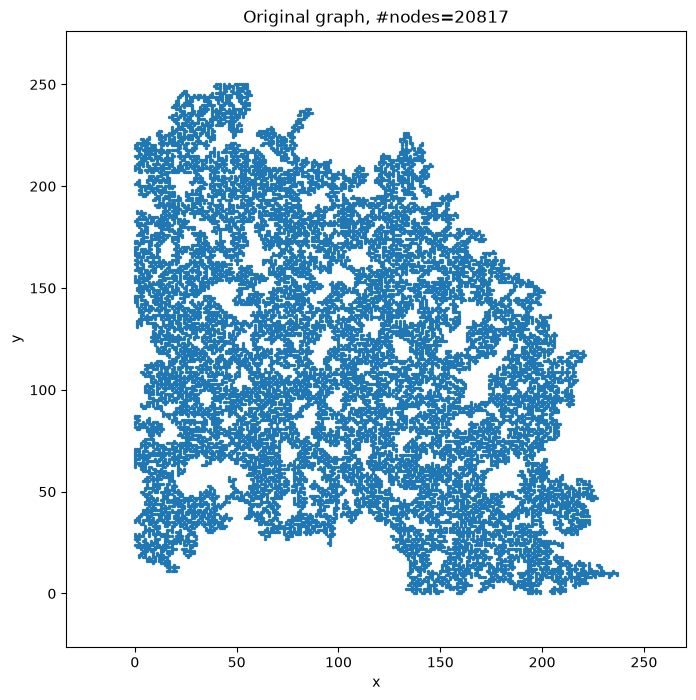

In [8]:
# Plot the graph
plt.figure(figsize=(8, 8))
kn.view.plot_graph2d(g, **options)
plt.title(f'Original graph, #nodes={g.number_of_nodes()}')
plt.show()

### Computing random walk dimension - using the dedicated function

In [9]:
# Set edge weight : inverse length
# --------------------------------
# Inverse of edge length (here: all length are equal to one)
length_inv = {e: 1.0/np.sqrt(np.sum((np.asarray(g.nodes[e[0]]['pos']) - np.asarray(g.nodes[e[1]]['pos']))**2)) for e in g.edges()}

nx.set_edge_attributes(g, length_inv, 'length_inv')

Compute nsteps [outbox diagonal / mean edge length]
Do random walks (10000 random walks of 344 time steps)
Progress:   1% (100 random walk(s) of 10000)
Progress:   2% (200 random walk(s) of 10000)
Progress:   3% (300 random walk(s) of 10000)
Progress:   4% (400 random walk(s) of 10000)
Progress:   5% (500 random walk(s) of 10000)
Progress:   6% (600 random walk(s) of 10000)
Progress:   7% (700 random walk(s) of 10000)
Progress:   8% (800 random walk(s) of 10000)
Progress:   9% (900 random walk(s) of 10000)
Progress:  10% (1000 random walk(s) of 10000)
Progress:  11% (1100 random walk(s) of 10000)
Progress:  12% (1200 random walk(s) of 10000)
Progress:  13% (1300 random walk(s) of 10000)
Progress:  14% (1400 random walk(s) of 10000)
Progress:  15% (1500 random walk(s) of 10000)
Progress:  16% (1600 random walk(s) of 10000)
Progress:  17% (1700 random walk(s) of 10000)
Progress:  18% (1800 random walk(s) of 10000)
Progress:  19% (1900 random walk(s) of 10000)
Progress:  20% (2000 random 

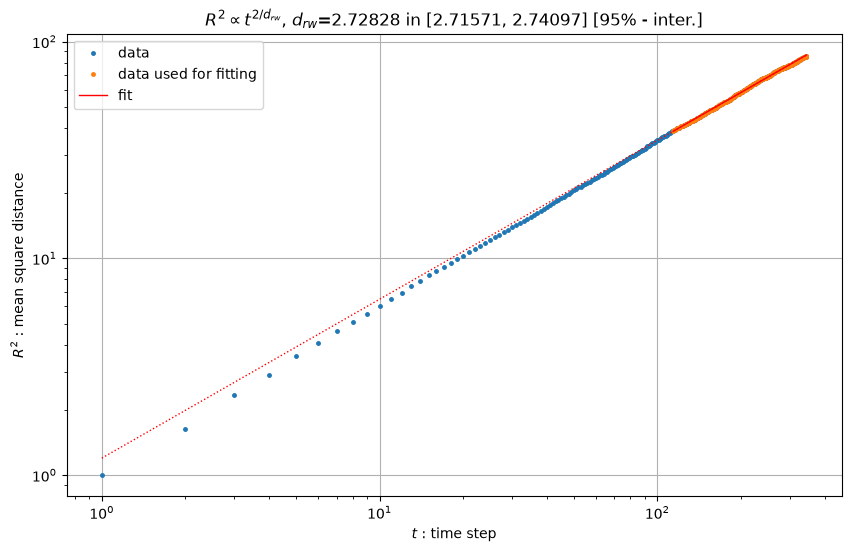

In [10]:
# Set figure (next computation makes a plot)
plt.figure(figsize=(10, 6))

# Compute random walk dimension (- and make plot)
# - parameters for fitting line on log-log plot
nrw = 10000                          # number of random walks
nsteps = None                        # number of time steps per random walk (None: automatically set)
data_points_removed_first_fraction = 0.33 # part of the points removed from the beginning to do the fit
data_points_removed_last_fraction = 0.0   # part of the points removed from the end to do the fit
confidence_level = 0.95              # confidence level for fitting
edge_weight='length_inv'             # edge weight, proportional to probabilities of choosing neighbors

out_dict = kn.tools.graph_random_walk_dimension(
        g,
        nrw=nrw,
        nsteps=nsteps,
        nsteps_max=10000,
        edge_weight=edge_weight,
        pos_attr='pos',
        u0=None, 
        data_points_removed_first_fraction=data_points_removed_first_fraction,
        data_points_removed_last_fraction=data_points_removed_last_fraction,
        confidence_level=confidence_level,
        return_poly_fit_params=True,
        return_poly_fit_params_cov=True,
        return_index_used_for_fit=True,
        return_rw_square_dist_mean=True,
        return_rw_square_dist_full=False,
        seed=2351,
        verbose=2,
        make_plot=True,
        plot_in_log_scale=True)

# Show plot
plt.show()

In [11]:
# Show output dictionary (keys and type of values)
for k, v in out_dict.items():
    print(f'key = {k:30s}: value type {type(v)}')

key = drw                           : value type <class 'numpy.float64'>
key = drw_lim_min                   : value type <class 'numpy.float64'>
key = drw_lim_max                   : value type <class 'numpy.float64'>
key = confidence_level              : value type <class 'float'>
key = poly_fit_params               : value type <class 'numpy.ndarray'>
key = poly_fit_params_cov           : value type <class 'numpy.ndarray'>
key = index_used_for_fit            : value type <class 'list'>
key = rw_square_dist_mean           : value type <class 'numpy.ndarray'>


In [12]:
# Get result from the output dictionary
# - random walk dimension
drw = out_dict['drw']
drw_lim_min = out_dict['drw_lim_min']
drw_lim_max = out_dict['drw_lim_max']
confidence_level = out_dict['confidence_level']

# - square distance mean, for each time step
rw_square_dist_mean = out_dict['rw_square_dist_mean']
# # - all square distances
# rw_square_dist_full = out_dict['rw_square_dist_full']

# - parameters of the fitted polynom (line in log-log scale)
poly_fit_params     = out_dict['poly_fit_params']
poly_fit_params_cov = out_dict['poly_fit_params_cov']
# - starting index of data points sequence used for fitting
index_used_for_fit = out_dict['index_used_for_fit']

In [13]:
# Print random walk dimension
print(f'Random walk dimension = {drw:.5f}, in [{drw_lim_min:.5f}, {drw_lim_max:.5f}] [{100*confidence_level:.2g}% - inter.]')

Random walk dimension = 2.72828, in [2.71571, 2.74097] [95% - inter.]


### Adapt the fit of the line on the log-log plot (if needed)
The function `kn.tools.graph_random_walk_dimension_update` allows to update the computation of the random walk dimension (without re-doing random walks between pairs of nodes) by adapting the points used for fitting the line on the log-log plot by changing the parameters `data_points_removed_first_fraction`, `data_points_removed_last_fraction` (and `confidence_interval`). 

Note that using the same parameters gives the same results and allows to re-do the plot of the fit. Alternatively, the function `kn.tools.plot_fit_random_walk_dimension` can be used to re-do the plot.

Compute random walk dimension (line fitting on log-log plot of mean square distance as function of time step)
Fitting on 172 points (over 344)


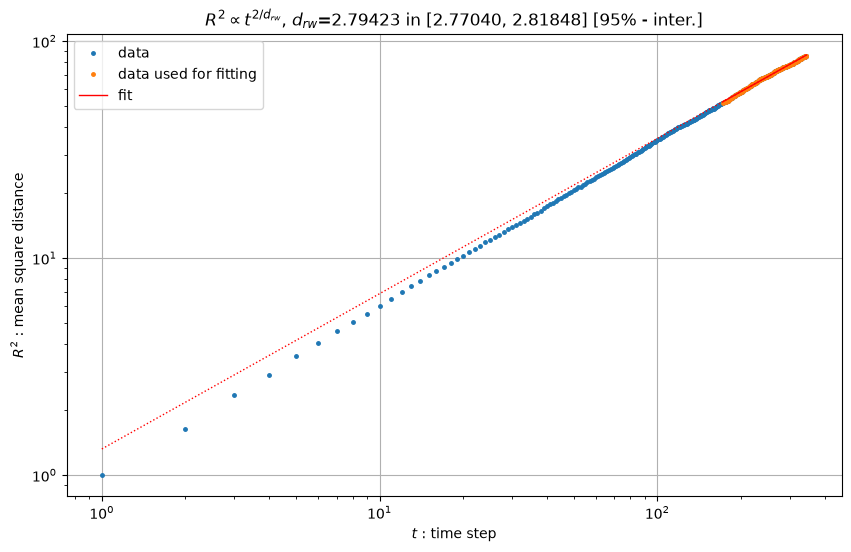

In [16]:
# out_dict_save = out_dict.copy() # save a copy of the results (if wanted)

# Set figure (next computation makes a plot)
plt.figure(figsize=(10, 6))

out_dict = kn.tools.graph_random_walk_dimension_update(
        out_dict,
        data_points_removed_first_fraction=0.5,
        data_points_removed_last_fraction=0.0,
        confidence_level=0.95,
        verbose=1,
        make_plot=True,
        plot_in_log_scale=True)

# Show plot
plt.show()

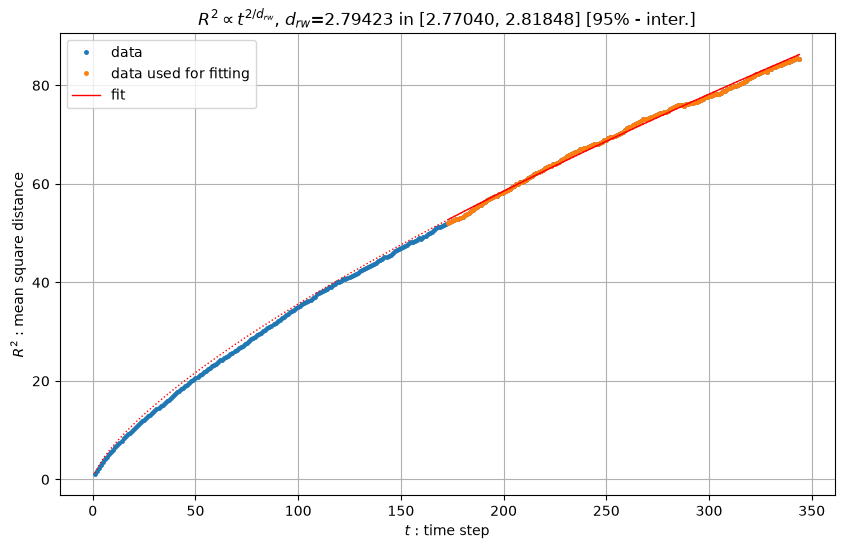

In [17]:
# Re-do the plot (not in log-log scale)

# Set figure
plt.figure(figsize=(10, 6))

y_all = out_dict['rw_square_dist_mean']
x_all = np.arange(1, len(y_all)+1)
n1, n2 = out_dict['index_used_for_fit']
x = x_all[n1:n2]
y = y_all[n1:n2]
drw = out_dict['drw']
drw_lim_min = out_dict['drw_lim_min']
drw_lim_max = out_dict['drw_lim_max']
confidence_level = out_dict['confidence_level']
poly_fit_params = out_dict['poly_fit_params']

kn.tools.plot_fit_random_walk_dimension(
    x_all, y_all, x, y, 
    drw, drw_lim_min, drw_lim_max, confidence_level, poly_fit_params, 
    plot_fit=True, plot_in_log_scale=False)

# Show plot
plt.show()

## Random walks - other tools

### Single random walk
The function `kn.tools.graph_random_walk` performs a random walk starting at a given node with a given number of (time) steps. At each step, the walker randomly chooses an edge from the currently visited node, the probability distribution is proportional to the edge weights (all the same if not given). The function returns the list of visited nodes (labels).


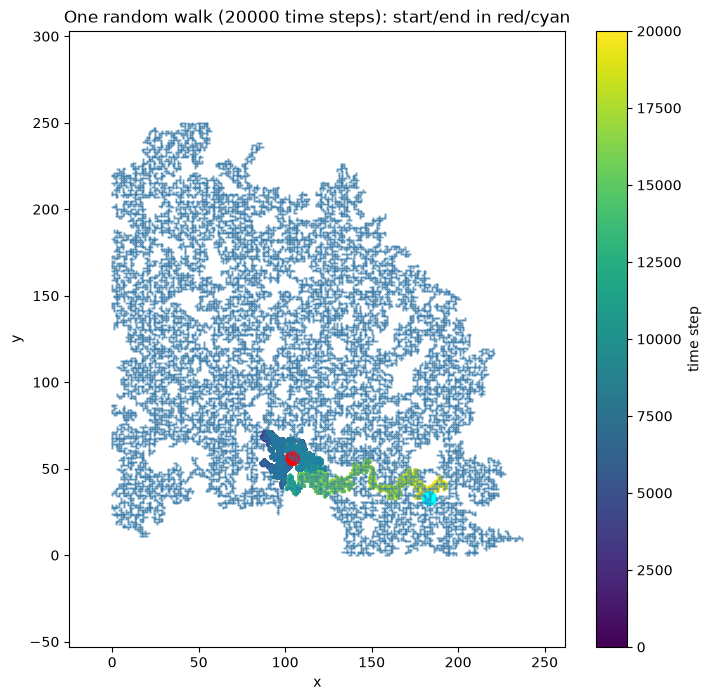

In [34]:
# One random walk
# ---------------
node_source = 4521
nsteps = 20000
seed = 835
rw = kn.tools.graph_random_walk(g, node_source, nsteps, edge_weight=None, seed=seed)
# -> rw : list of length nsteps + 1 of node labels visited during the random walk

# Plot the graph with the random walk
# -----------------------------------
# Get positions of visited nodes
rw_pos = np.asarray([g.nodes[u]['pos'] for u in rw]) # array of shape (nsteps + 1, 2)

# Options for plot of 2D graph
options = {
    'node_size'   : 3,           # node size
    'linewidths'  : 0,           # node border width       
    # 'edgecolors'  : 'gray',    # node border color
    'node_color'  : 'tab:blue',  # node color (default - if no attribute is specified or for nan values)
    'width'       : 1,           # edge width
    'edge_color'  : 'gray',      # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : False,        # show node labels ?
    'font_size'   : 8,           # font size for labels
    #
    # axes
    'show_ticks'  : True,        # show ticks ?
    'axis_equal'  : True         # aspect ratio equal ?
}

plt.figure(figsize=(8, 8))
kn.view.plot_graph2d(g, alpha=0.5, **options)
# add random walk
plt.scatter(rw_pos[:, 0], rw_pos[:, 1], c=np.arange(len(rw_pos)), cmap='viridis', s=3, label='random walk')
plt.colorbar(label='time step')

# add start and end points
plt.scatter(*g.nodes[node_source]['pos'], marker='o', s=100, color='red', alpha=1.0, label='start')
plt.scatter(*g.nodes[rw[-1]]['pos'], marker='o', s=100, color='cyan', alpha=1, label='end')

# plt.legend()
plt.title(f'One random walk ({nsteps} time steps): start/end in red/cyan')

plt.show()


### Other representations
Coloring nodes and/or edges as function of the number of times they are visited during the random walk.


In [45]:
# Set node and edge attributes for other representation of the random walk
# ------------------------------------------------------------------------
# Set node attribute 'rw_counts': number of times a node is visited during the random walk
rw_counts = {u: 0 for u in g.nodes()}
for u in rw:
    rw_counts[u] += 1

nx.set_node_attributes(g, rw_counts, 'rw_counts')

# Set edge attribute 'rw_edge_counts': number of times an edge is visited during the random walk
rw_edge_counts = {e: 0 for e in g.edges()}
nx.set_edge_attributes(g, rw_edge_counts, 'rw_edge_counts')
for k in range(len(rw)-1):
    g.edges[(rw[k], rw[k+1])]['rw_edge_counts'] += 1

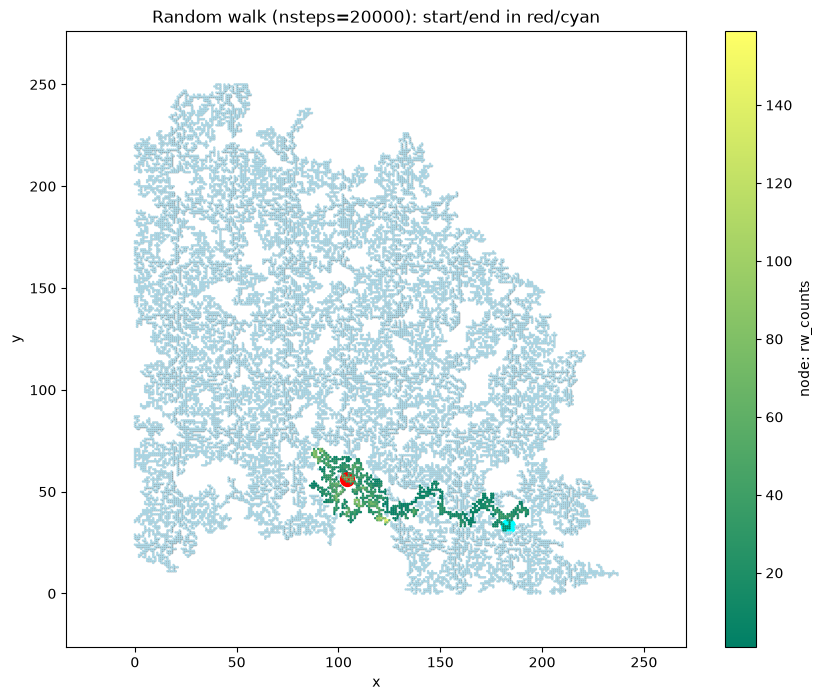

In [47]:
# Plot graph coloring nodes as function of the number of times they are visited during the random walk
# ---------------------------------------------------------------------------------------------------
# Color map for nodes
# cmap = plt.get_cmap('cividis')
cmap = plt.get_cmap('summer')
cmap.set_under('lightblue')

# # Color map for edges
# # edge_cmap = plt.get_cmap('viridis')
# edge_cmap = plt.get_cmap('spring')
# edge_cmap.set_under('gray')

# Options for plot of 2D graph
options = {
    # nodes
    'node_size'   : 3,           # node size
    'linewidths'  : 0,           # node border width       
    'edgecolors'  : 'gray',      # node border color
    # 'node_color'  : 'lightblue',      # node color (default - if no attribute is specified or for nan values)
    'cmap'        : cmap,        # node color map (for attribute values)
    'vmin'        : 1,           # min value for color map (node)
    'with_labels' : False,        # show node labels ?
    # 'font_size'   : 8,           # font size for labels
    #
    # edges
    'width'       : 1,           # edge width
    'edge_color'  : 'gray',      # edge color (default - if no attribute is specified or for nan values)
    # 'edge_cmap'   : edge_cmap,   # edge color map (for attribute values)
    # 'edge_vmin'   : 1,           # min value for color map (edge)
    #
    # axes
    'show_ticks'  : True,        # show ticks ?
    'axis_equal'  : True         # aspect ratio equal ?
}

# Plot the graph
plt.figure(figsize=(10, 8))
kn.view.plot_graph2d(
    g, 
    node_attr='rw_counts', 
    # edge_attr='rw_edge_counts',
    **options)
plt.scatter(*g.nodes[node_source]['pos'], marker='o', s=100, color='red', alpha=1)
plt.scatter(*g.nodes[rw[-1]]['pos'], marker='o', s=100, color='cyan', alpha=1)
plt.title(f'Random walk (nsteps={nsteps}): start/end in red/cyan')
plt.show()

### Random walk escape time

The function `kn.tools.graph_random_walk_escape_time` computes the exit time for a random walk to escape an area, for several random walks. A total of `nrw` random walks are performed, each one starts at a node `u0` if given or at a random node otherwise and the walker stops as soon as the Euclidean distance between the currently visited node and the starting node is greater than the given distance `dist`. At each step, the walker randomly chooses an edge from the currently visited node, the probability distribution is proportional to the edge weights (all the same if not given). The function returns the array of the first time step of escape.

In [51]:
node_source = 4521   # starting node
nrw = 1000           # number of random walks
dist = 20.0          # distance to escape
nsteps_max = 100000  # maximal number of steps for one random walk
seed = 19243

rw_escape_time_arr = kn.tools.graph_random_walk_escape_time(
                        g, nrw, dist,
                        edge_weight=None, 
                        nsteps_max=nsteps_max, 
                        u0=node_source, 
                        seed=seed, 
                        check_dist=True, 
                        verbose=1)


Progress:   1% (10 random walk(s) of 1000)
Progress:   2% (20 random walk(s) of 1000)
Progress:   3% (30 random walk(s) of 1000)
Progress:   4% (40 random walk(s) of 1000)
Progress:   5% (50 random walk(s) of 1000)
Progress:   6% (60 random walk(s) of 1000)
Progress:   7% (70 random walk(s) of 1000)
Progress:   8% (80 random walk(s) of 1000)
Progress:   9% (90 random walk(s) of 1000)
Progress:  10% (100 random walk(s) of 1000)
Progress:  11% (110 random walk(s) of 1000)
Progress:  12% (120 random walk(s) of 1000)
Progress:  13% (130 random walk(s) of 1000)
Progress:  14% (140 random walk(s) of 1000)
Progress:  15% (150 random walk(s) of 1000)
Progress:  16% (160 random walk(s) of 1000)
Progress:  17% (170 random walk(s) of 1000)
Progress:  18% (180 random walk(s) of 1000)
Progress:  19% (190 random walk(s) of 1000)
Progress:  20% (200 random walk(s) of 1000)
Progress:  21% (210 random walk(s) of 1000)
Progress:  22% (220 random walk(s) of 1000)
Progress:  23% (230 random walk(s) of 100

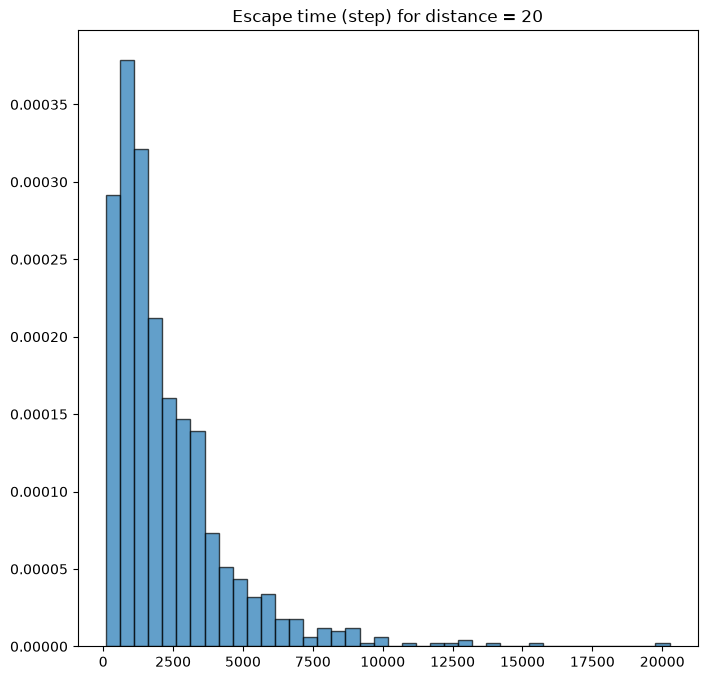

In [52]:
plt.figure(figsize=(8,8))
plt.hist(rw_escape_time_arr, bins=40, density=True, color='tab:blue', alpha=0.7, edgecolor='black', linewidth=1.0)
plt.title(f'Escape time (step) for distance = {dist:.3g}')
plt.show()

### Random walk : mean square distance

The function `kn.tools.graph_random_walk_square_distance` computes the mean and square distance after each time step, for several random walks. A total of `nrw` random walks of `nsteps` are performed, each one starts at node `u0` if given or at a random node otherwise and the mean of Euclidean square distance from the starting node, after each time step, is computed. At each step, the walker randomly chooses an edge from the currently visited node, the probability distribution is proportional to the edge weights (all the same if not given).

In [53]:
node_source = 4521   # starting node
nrw = 10000           # number of random walks
nsteps = 1000       # number of time steps
seed = 1242

rw_mean_square_dist_arr = kn.tools.graph_random_walk_square_distance(
                            g, nrw, nsteps,
                            edge_weight=None, 
                            u0=node_source, 
                            seed=seed, 
                            return_full_array=False,
                            verbose=1)


Progress:   1% (100 random walk(s) of 10000)
Progress:   2% (200 random walk(s) of 10000)
Progress:   3% (300 random walk(s) of 10000)
Progress:   4% (400 random walk(s) of 10000)
Progress:   5% (500 random walk(s) of 10000)
Progress:   6% (600 random walk(s) of 10000)
Progress:   7% (700 random walk(s) of 10000)
Progress:   8% (800 random walk(s) of 10000)
Progress:   9% (900 random walk(s) of 10000)
Progress:  10% (1000 random walk(s) of 10000)
Progress:  11% (1100 random walk(s) of 10000)
Progress:  12% (1200 random walk(s) of 10000)
Progress:  13% (1300 random walk(s) of 10000)
Progress:  14% (1400 random walk(s) of 10000)
Progress:  15% (1500 random walk(s) of 10000)
Progress:  16% (1600 random walk(s) of 10000)
Progress:  17% (1700 random walk(s) of 10000)
Progress:  18% (1800 random walk(s) of 10000)
Progress:  19% (1900 random walk(s) of 10000)
Progress:  20% (2000 random walk(s) of 10000)
Progress:  21% (2100 random walk(s) of 10000)
Progress:  22% (2200 random walk(s) of 1000

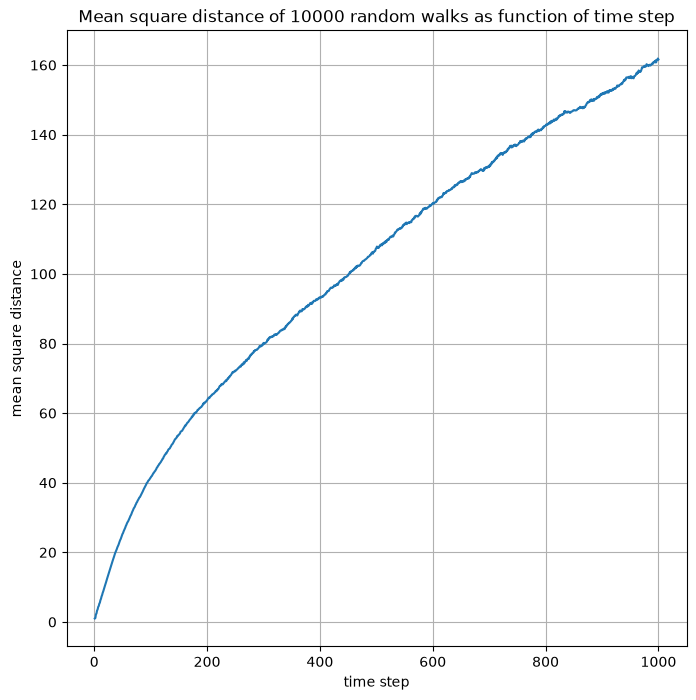

In [ ]:
plt.figure(figsize=(8,8))
plt.plot(range(1, len(rw_mean_square_dist_arr)+1), rw_mean_square_dist_arr)
plt.grid()
plt.xlabel('time step')
plt.ylabel('mean square distance')
plt.title(f'Mean square distance of {nrw} random walks as function of time step')
plt.show()

Get the full array of distance for computing other statistics.

In [55]:
node_source = 4521   # starting node
nrw = 10000           # number of random walks
nsteps = 1000       # number of time steps
seed = 1242

rw_mean_square_dist_arr, rw_square_dist = kn.tools.graph_random_walk_square_distance(
                            g, nrw, nsteps,
                            edge_weight=None, 
                            u0=node_source, 
                            seed=seed, 
                            return_full_array=True,
                            verbose=1)


Progress:   1% (100 random walk(s) of 10000)
Progress:   2% (200 random walk(s) of 10000)
Progress:   3% (300 random walk(s) of 10000)
Progress:   4% (400 random walk(s) of 10000)
Progress:   5% (500 random walk(s) of 10000)
Progress:   6% (600 random walk(s) of 10000)
Progress:   7% (700 random walk(s) of 10000)
Progress:   8% (800 random walk(s) of 10000)
Progress:   9% (900 random walk(s) of 10000)
Progress:  10% (1000 random walk(s) of 10000)
Progress:  11% (1100 random walk(s) of 10000)
Progress:  12% (1200 random walk(s) of 10000)
Progress:  13% (1300 random walk(s) of 10000)
Progress:  14% (1400 random walk(s) of 10000)
Progress:  15% (1500 random walk(s) of 10000)
Progress:  16% (1600 random walk(s) of 10000)
Progress:  17% (1700 random walk(s) of 10000)
Progress:  18% (1800 random walk(s) of 10000)
Progress:  19% (1900 random walk(s) of 10000)
Progress:  20% (2000 random walk(s) of 10000)
Progress:  21% (2100 random walk(s) of 10000)
Progress:  22% (2200 random walk(s) of 1000

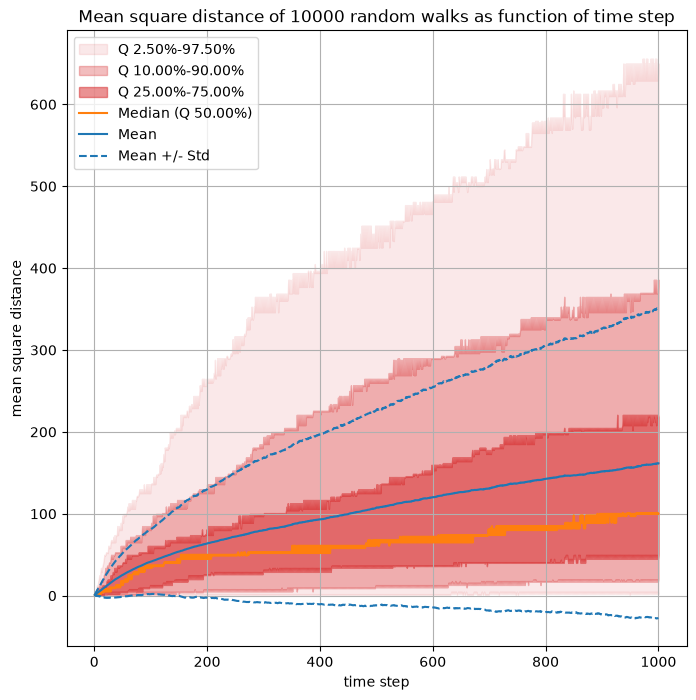

In [61]:
# Compute stats
rw_square_dist_mean = np.mean(rw_square_dist, axis=0)
rw_square_dist_std = np.std(rw_square_dist, axis=0)

# q = np.array([0.0, 0.025, 0.25, 0.5, 0.75, 0.975, 1.0])
q = np.array([0.025, 0.10, 0.25, 0.5, 0.75, 0.90, 0.975])
rw_square_dist_q = np.quantile(rw_square_dist, q=q, axis=0)

alpha_q = np.linspace(0.1, 0.5, len(q)//2)

# Figure
plt.figure(figsize=(8,8))
# Quantiles
for i in range(len(q)//2):
    plt.fill_between(np.arange(1, nsteps+1), rw_square_dist_q[i], rw_square_dist_q[len(q)-i-1], color='tab:red', alpha=alpha_q[i], label=f'Q {100*q[i]:.2f}%-{100*q[len(q)-i-1]:.2f}%')

# Median
plt.plot(np.arange(1, nsteps+1), rw_square_dist_q[len(q)//2], color='tab:orange', label=f'Median (Q {100*q[len(q)//2]:.2f}%)')

# Mean
plt.plot(np.arange(1, nsteps+1), rw_square_dist_mean, color='tab:blue', label='Mean')
# Mean +/- std
plt.plot(np.arange(1, nsteps+1), rw_square_dist_mean+rw_square_dist_std, color='tab:blue', linestyle='dashed', label='Mean +/- Std')
plt.plot(np.arange(1, nsteps+1), rw_square_dist_mean-rw_square_dist_std, color='tab:blue', linestyle='dashed')

plt.grid()
plt.legend()
plt.xlabel('time step')
plt.ylabel('mean square distance')
plt.title(f'Mean square distance of {nrw} random walks as function of time step')
plt.show()